# HoneyComb120 后选择测量：相关比 $R=S(0)/S(\Delta q)$

对照论文 Yu 等 (arXiv:2310.10601) 的 Eq. (4)(5)。数据来自 `phy_update_M`（A 子格乘 $e^{-2\beta}$ 的后选择），目录结构为 `beta<β>/L<L>/`，每个 U 一个 csv，每行一个 sweep，列为 `Ek, Eu, SDW0, SDW1`。

- 设置：初态 `Initial="V"`（饱和 Néel 态），$\Delta t=0.05$，$\Theta=0.15L$。代码里 $N_t=2\Theta/\Delta t$，所以论文的投影总长是 $\tau=2\Theta$，即 $\tau/L=0.3$。
- $R=\overline{\mathrm{SDW0}}/\overline{\mathrm{SDW1}}$：SDW0 是 $S(0)$，SDW1 是最短动量方向平均的 $S(\Delta q)$。先对 sweep 求平均再相除，误差用分 bin 的 jackknife。
- 文件名里的 U、L、Θ、Δt 用 `DP_Lib.parse_filename` 解析，β 取自文件夹名。
- 长表 `df` 里 `X0` 是分母（SDW1），`X1` 是分子（SDW0），`dX0`、`dX1` 是它们的标准误。
- `snr0 = |X0| / dX0` 是分母的信噪比。它接近 1 说明分母和 0 无法区分，这时比值不可靠，下面的诊断表会给出每个 (obs, β, L) 的最小值。
- 读 csv 时会丢掉含空值的残行（任务还在写的最后一行），列数不是 4 的旧文件会被跳过并打印出来，所以任务没跑完时也可以直接运行。
- 目的：看不同尺寸 L 的 R–U 曲线在论文的 $U_c\approx3.91$ 附近有没有交点。论文说 $\tau/L=0.3$ 时小尺寸的交点会偏小。

In [8]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd().resolve()
for p in [HERE, *HERE.parents]:          # 向上找 DP_Lib.py（在 code/KAPDQMC/ 下）
    if (p / 'DP_Lib.py').exists():
        sys.path.insert(0, str(p))
        break
import DP_Lib as dp

DATA = HERE            # 含 beta*/L*/ 的目录
THROW = 0              # 每个 csv 丢掉前 THROW 行（热化阶段）
NBIN = 20              # jackknife 分 bin 数
UC0 = 3.91             # 论文的临界点 Uc = 3.91(3)
NCOL = 4               # csv 列序：Ek, Eu, SDW0, SDW1
# 观测量 -> (分母列, 分子列)。R = S(0)/S(Δq) = SDW0/SDW1，所以分母是 SDW1（列 3），分子是 SDW0（列 2）
OBS = {'SDW': (3, 2)}
LABEL = {'SDW': 'R = S(0)/S(Δq)'}

In [9]:
# R = mean(x1)/mean(x0)，连续分 bin 的 jackknife 误差
def ratio_jk(s0, s1, nbin=NBIN):
    nb = min(nbin, len(s0))
    m = len(s0) // nb
    a0 = np.asarray(s0, float)[:nb * m].reshape(nb, m).sum(axis=1)
    a1 = np.asarray(s1, float)[:nb * m].reshape(nb, m).sum(axis=1)
    T0, T1 = a0.sum(), a1.sum()
    if nb < 2:
        return T1 / T0, np.nan
    rj = (T1 - a1) / (T0 - a0)
    return T1 / T0, np.sqrt((nb - 1) / nb * np.sum((rj - rj.mean()) ** 2))


def load_all(root=DATA, throw=THROW):
    rows = []
    for bdir in sorted(Path(root).glob('beta*')):
        if not bdir.is_dir():
            continue
        beta = float(bdir.name[len('beta'):])
        for ldir in sorted(bdir.glob('L*')):
            if not ldir.is_dir():
                continue
            for f in sorted(ldir.glob('*.csv')):
                par = dp.parse_filename(f.name)          # DP_Lib：解析 U、size、Θ、Δt、BS
                L = par['size'][0]
                if ldir.name != 'L' + str(L):
                    print('警告：文件夹名与文件名里的 L 不一致', f)
                try:
                    d = pd.read_csv(f, header=None).to_numpy(float)
                except pd.errors.EmptyDataError:
                    continue
                d = d[~np.isnan(d).any(axis=1)][throw:]   # 任务还在跑时最后一行可能只写了一半，丢掉
                if d.shape[1] != NCOL or len(d) < 2:
                    print('跳过', f, d.shape)
                    continue
                for obs, (i0, i1) in OBS.items():
                    r, e = ratio_jk(d[:, i0], d[:, i1])
                    rows.append([obs, beta, L, float(par['U']), par['Θ'], par['Δt'], len(d),
                                 d[:, i0].mean(), dp.sem(d[:, i0]), d[:, i1].mean(), dp.sem(d[:, i1]), r, e])
    cols = ['obs', 'beta', 'L', 'U', 'Theta', 'dt', 'n', 'X0', 'dX0', 'X1', 'dX1', 'ratio', 'err']
    out = pd.DataFrame(rows, columns=cols)
    out['snr0'] = out.X0.abs() / out.dX0
    return out.sort_values(['obs', 'beta', 'L', 'U']).reset_index(drop=True)


df = load_all()
assert len(df) > 0, '没有读到任何有效 csv：检查 DATA 路径、beta*/L*/ 目录，以及列数是否为 NCOL=' + str(NCOL)
betas = sorted(df.beta.unique())
Ls = sorted(df.L.unique())
print(len(df) // len(OBS), '个文件；beta =', betas, '；L =', Ls, '；obs =', list(OBS))
df[df.obs == 'SDW'].groupby(['beta', 'L']).size().unstack()

26 个文件；beta = [0.0] ；L = [6, 9, 12] ；obs = ['SDW']


L,6,9,12
beta,,,
0.0,10,10,6


## ratio 汇总表

β>0 时数值很小，用科学计数法显示。

In [10]:
for obs in OBS:
    print(LABEL[obs])
    tab = df[df.obs == obs].pivot_table(index=['beta', 'L'], columns='U', values='ratio')
    with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 220):
        display(tab)

R = S(0)/S(Δq)


U         3     3.3   3.5   3.6   3.7   3.8   3.9   4     4.1   4.5
beta L                                                             
0    6  21.28 24.02 26.41 27.78  28.5 29.83 31.37 32.75 34.12  39.6
     9  19.01 23.01 25.82 27.48 29.02 30.59  32.3 34.21  36.8 45.27
     12 16.78 22.18 26.12 27.23 29.28 30.96   NaN   NaN   NaN   NaN

## 每个 β 一张图：不同 L 的 R 随 U 变化

每个观测量一张大图，每个子图的纵轴独立。虚线是论文的 U=3.91。

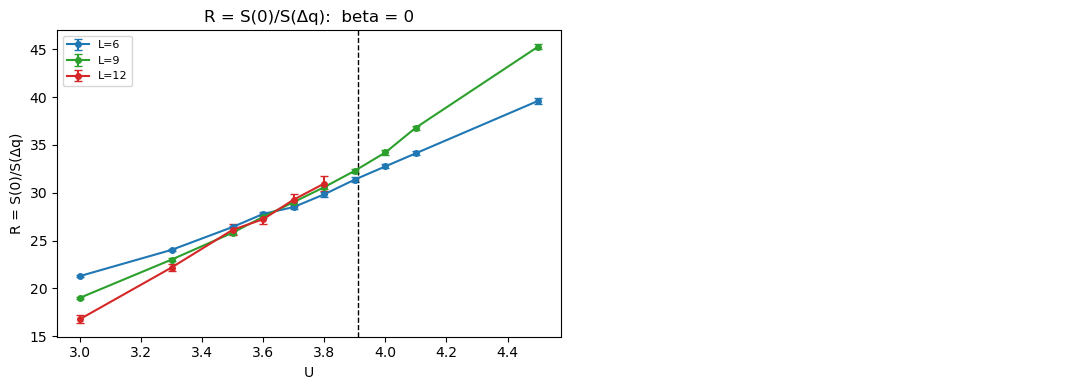

In [11]:
LCOL = {3: 'gray', 6: 'tab:blue', 9: 'tab:green', 12: 'tab:red'}


def plot_beta(ax, d, obs, beta):
    for L, g in d[d.beta == beta].groupby('L'):
        c = LCOL.get(int(L), 'k')
        ax.errorbar(g.U, g.ratio, yerr=g.err, marker='o', ms=4, capsize=3, color=c, ecolor=c, label='L=' + str(int(L)))
    ax.axvline(UC0, color='k', ls='--', lw=1)
    ax.set_xlabel('U')
    ax.set_ylabel(LABEL[obs])
    ax.set_title(LABEL[obs] + ':  beta = ' + format(beta, 'g'))
    ax.legend(loc='best', fontsize=8)


ncol = 2
nrow = -(-len(betas) // ncol)
for obs in OBS:
    d = df[df.obs == obs]
    fig, axs = plt.subplots(nrow, ncol, figsize=(11, 4 * nrow), squeeze=False)
    for ax, b in zip(axs.ravel(), betas):
        plot_beta(ax, d, obs, b)
    for ax in axs.ravel()[len(betas):]:
        ax.axis('off')
    fig.tight_layout()
    # fig.savefig('ratio_all_beta_' + obs + '_py.png', dpi=150)
    plt.show()

## 相邻尺寸的交点（crossover）

相邻两个 L 的 ratio 曲线在公共的 U 点上做差，符号变化处线性插值得到交点。交点只可能出现在已扫描的 U 范围内；没有符号变化的相邻 L 对不会出现在表里。

In [12]:
def crossings(d, obs, beta):
    out = []
    Lb = sorted(d[d.beta == beta].L.unique())
    for L1, L2 in zip(Lb[:-1], Lb[1:]):
        a = d[(d.beta == beta) & (d.L == L1)].set_index('U').ratio
        b = d[(d.beta == beta) & (d.L == L2)].set_index('U').ratio
        us = sorted(a.index.intersection(b.index))
        diff = (a[us] - b[us]).to_numpy()
        for i in range(len(us) - 1):
            if diff[i] * diff[i + 1] < 0:
                u = us[i] + (us[i + 1] - us[i]) * diff[i] / (diff[i] - diff[i + 1])
                out.append((obs, beta, int(L1), int(L2), u))
    return pd.DataFrame(out, columns=['obs', 'beta', 'L1', 'L2', 'U_cross'])


parts = [crossings(df[df.obs == obs], obs, b) for obs in OBS for b in betas]
parts = [p for p in parts if len(p)]
cross = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=['obs', 'beta', 'L1', 'L2', 'U_cross'])
cross

,obs,beta,L1,L2,U_cross
0,SDW,0.0,6,9,3.637143
1,SDW,0.0,9,12,3.446758
2,SDW,0.0,9,12,3.555095
3,SDW,0.0,9,12,3.648802


## 同一个 L 下叠加不同 β

纵轴用 symlog（线性阈值 1e-4），这样不同 β 的 R 能画在同一张图里。共用一个图例，放在图外。

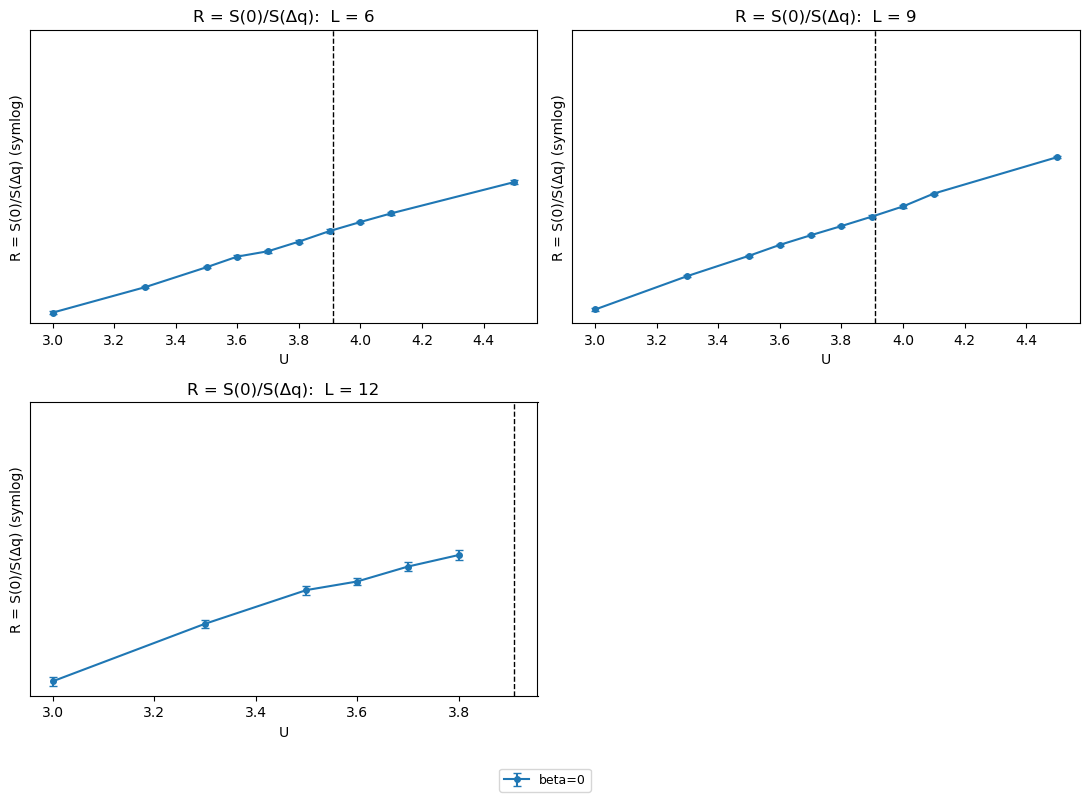

In [13]:
nr = -(-len(Ls) // 2)
for obs in OBS:
    d = df[df.obs == obs]
    fig, axs = plt.subplots(nr, 2, figsize=(11, 4 * nr), squeeze=False)
    for ax, L in zip(axs.ravel(), Ls):
        for ib, b in enumerate(betas):
            g = d[(d.L == L) & (d.beta == b)]
            c = 'C' + str(ib)
            ax.errorbar(g.U, g.ratio, yerr=g.err, marker='o', ms=4, capsize=3, color=c, ecolor=c, label='beta=' + format(b, 'g'))
        ax.axvline(UC0, color='k', ls='--', lw=1)
        ax.set_yscale('symlog', linthresh=1e-4)
        ax.set_xlabel('U')
        ax.set_ylabel(LABEL[obs] + ' (symlog)')
        ax.set_title(LABEL[obs] + ':  L = ' + format(L, 'g'))
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi * 2 if hi > 0 else hi / 2)   # 顶部留出空间，免得最高的点贴着上边框
    for ax in axs.ravel()[len(Ls):]:
        ax.axis('off')
    h, l = axs.ravel()[0].get_legend_handles_labels()
    fig.legend(h, l, loc='lower center', ncol=len(betas), fontsize=9)   # 共用图例放在图外，不盖住曲线
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    # fig.savefig('ratio_by_L_' + obs + '_py.png', dpi=150)
    plt.show()

## 诊断：分母、分子本身随 U 变不变，分母是否和 0 区分得开

`X0` 是分母（SDW1，即 $S(\Delta q)$），`X1` 是分子（SDW0，即 $S(0)$）。`*_spread` 是同一 (obs, β, L) 下各 U 点的均值的相对涨落 (max−min)/|mean|。如果它接近 0，说明态已经和 U 无关，这时 R 不能再当有序/无序的判据。

`snr0_min` 是各 U 点上 |X0|/dX0 的最小值。它接近 1 说明分母和 0 无法区分，比值不可靠。

In [14]:
def rel_spread(x):
    return (x.max() - x.min()) / abs(x.mean())


diag = df.groupby(['obs', 'beta', 'L']).agg(X0_mean=('X0', 'mean'), X0_spread=('X0', rel_spread),
                                            X1_mean=('X1', 'mean'), X1_spread=('X1', rel_spread),
                                            snr0_min=('snr0', 'min'))
with pd.option_context('display.float_format', '{:.3e}'.format, 'display.width', 220, 'display.max_rows', 100):
    display(diag)

X0_mean  X0_spread   X1_mean  X1_spread  snr0_min
obs beta      L                                                     
SDW 0.000e+00 6  1.102e-02  1.487e-01 3.236e-01  4.653e-01 3.344e+02
              9  6.811e-03  1.160e-01 2.051e-01  7.339e-01 3.376e+02
              12 4.710e-03  1.704e-02 1.195e-01  5.541e-01 8.760e+01